# ADC: 7-bit SAR

One streamed transient per test: the input `Vd` steps once per 1 µs conversion and each conversion's code is read at the end of its slot. The ramp gives gain, offset, INL and DNL; the coherent sine gives SINAD, ENOB, THD and SFDR.

INL/DNL are limited by the sweep step, so the same sweep points are also run through a perfect ADC with the measured gain and offset. That floor is drawn in black; only what lies beyond it is the circuit.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sarlib import specs as S
from sarlib.analysis import read_raw, Report

DATA = Path('simulation/adc.sch')
a = S.adc
SP = a.SPECS
N = S.NCODE
G_IDEAL = N / S.vi.V_FS                # codes per volt of V+ - V-
rep = Report()

def conversions(path):
    """Per conversion: input, SAR-register code, d_out code, eoc, mean supply current (uA)."""
    R = read_raw(path)
    t = R['time']
    k = np.arange(int(np.floor((t[-1] - a.T_OUT) / a.T_CONV)) + 1)
    at = lambda name, t0: np.interp(t0 + k * a.T_CONV, t, R[name])
    code = sum((1 << b) * (at(f'v(d{b})', a.T_SAR) > 0.9) for b in range(1, 7)) + (at('v(d_out0)', a.T_OUT) > 0.9)
    dout = sum((1 << b) * (at(f'v(d_out{b})', a.T_OUT) > 0.9) for b in range(7))
    idd = np.array([-1e6 * R['i(vdd)'][(t >= n * a.T_CONV + a.T_IDD[0]) & (t <= n * a.T_CONV + a.T_IDD[1])].mean() for n in k])
    return pd.DataFrame(dict(vd=at('v(vd)', a.T_SAR), code=code, dout=dout, eoc=at('v(eoc)', a.T_OUT) > 0.9, idd=idd))

def transitions(vd, code):
    T = {k: 0.5 * (vd[i - 1] + vd[i]) for k in range(int(code.min()) + 1, int(code.max()) + 1) if (i := int(np.argmax(code >= k))) > 0}
    ks = np.array(sorted(T)); Tv = np.array([T[k] for k in ks])
    return ks, Tv, *np.polyfit(ks, Tv, 1)

def linearity(vd, code, g, c, w):
    ks, Tv, ta, tb = transitions(vd, code)
    return dict(inl_s=np.convolve(code + 0.5 - (g * vd + c), np.ones(w) / w, mode='valid'), ks=ks, ta=ta, tb=tb,
                inl_t=(Tv - (ta * ks + tb)) / ta, dnl_t=np.diff(Tv) / ta - 1.0, dnl_k=ks[:-1])

## Static transfer (ramp)

513 conversions, step 1.05 mV = 0.22 LSB, codes 8 .. 119
LSB 4.888 mV (ideal 4.914 mV), gain error +0.55 %, offset -0.01 LSB
INL from transitions 0.17 LSB (perfect ADC: 0.11); DNL -0.14 .. +0.08 (perfect ADC: -0.14 .. +0.08)


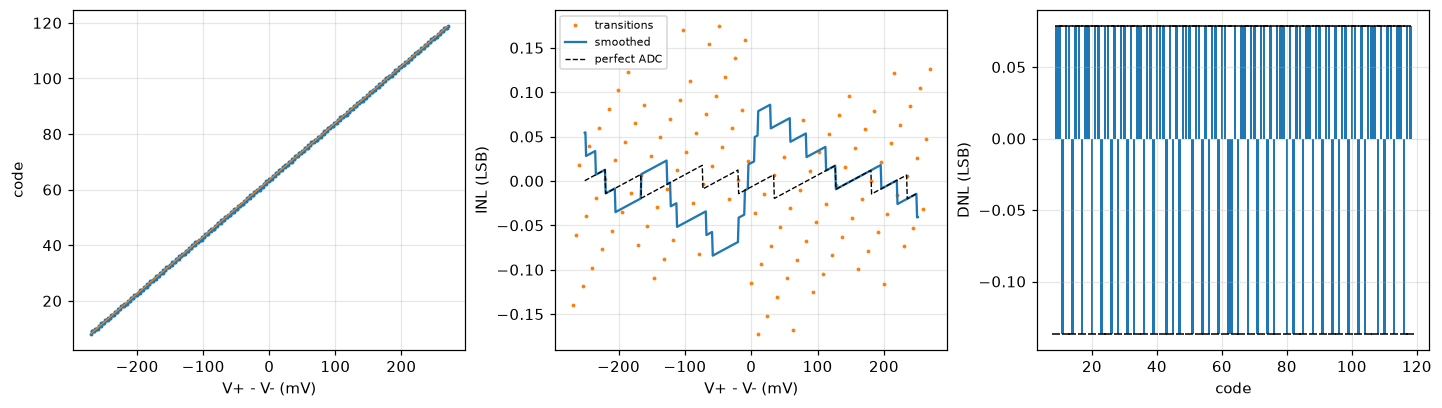

In [2]:
R = conversions(DATA / 'adc_ramp_a.raw').sort_values('vd')
rep.check('all conversions finished', f'{int((~R.eoc).sum())} unfinished', '== 0', bool(R.eoc.all()))
rep.check('d_out matches the SAR register', f'{int((R.code != R.dout).sum())} of {len(R)} differ', '== 0', bool((R.code == R.dout).all()))
vd, code = R.vd.values, R.code.values.astype(float)
g, c = np.polyfit(vd, code + 0.5, 1)
bad = np.abs(code + 0.5 - (g * vd + c)) > a.OUTLIER_LSB
vd, code = vd[~bad], code[~bad]
g, c = np.polyfit(vd, code + 0.5, 1)
step = float(np.median(np.diff(vd)))
w = max(3, int(round(a.SMOOTH_LSB / (step * g))))
cmin, cmax = int(code.min()), int(code.max())
meas = linearity(vd, code, g, c, w)
ideal = linearity(vd, np.clip(np.floor(g * vd + c), cmin, cmax), g, c, w)
inl_s, floor_s = np.abs(meas['inl_s']).max(), np.abs(ideal['inl_s']).max()
missing = [k for k in range(cmin, cmax + 1) if not np.any(code == k)]
reversals = int(np.sum(np.diff(code) < 0))
gain_err, offset = 100 * (g / G_IDEAL - 1), c - N / 2
print(f'{len(R)} conversions, step {1e3 * step:.2f} mV = {step * g:.2f} LSB, codes {cmin} .. {cmax}')
print(f'LSB {1e3 / g:.3f} mV (ideal {1e3 / G_IDEAL:.3f} mV), gain error {gain_err:+.2f} %, offset {offset:+.2f} LSB')
print(f"INL from transitions {np.abs(meas['inl_t']).max():.2f} LSB (perfect ADC: {np.abs(ideal['inl_t']).max():.2f}); "
      f"DNL {meas['dnl_t'].min():+.2f} .. {meas['dnl_t'].max():+.2f} (perfect ADC: {ideal['dnl_t'].min():+.2f} .. {ideal['dnl_t'].max():+.2f})")
rep.check('conversion errors', f'{int(bad.sum())} beyond +/-{a.OUTLIER_LSB} LSB', '== 0', not bad.any())
rep.check(f'INL, smoothed best fit ({w} pt)', f'{inl_s:.3f} LSB (sweep floor {floor_s:.2f})', f"<= {SP['inl_lsb_max']} LSB",
          inl_s + floor_s <= SP['inl_lsb_max'])
rep.check('no missing codes', f'{len(missing)} missing', '== 0', not missing)
rep.check('monotonic', f'{reversals} reversals', '== 0', reversals == 0)
rep.info('gain error / offset', f'{gain_err:+.2f} % / {offset:+.2f} LSB')

vd_s = np.convolve(vd, np.ones(w) / w, mode='valid')
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
axs[0].plot(1e3 * vd, code, '.', ms=3); axs[0].plot(1e3 * vd, g * vd + c - 0.5, lw=0.8)
axs[0].set(xlabel='V+ - V- (mV)', ylabel='code')
axs[1].plot(1e3 * (meas['ta'] * meas['ks'] + meas['tb']), meas['inl_t'], '.', ms=3, c='C1', label='transitions')
axs[1].plot(1e3 * vd_s, meas['inl_s'], c='C0', label='smoothed')
axs[1].plot(1e3 * vd_s, ideal['inl_s'], 'k--', lw=0.9, label='perfect ADC')
axs[1].set(xlabel='V+ - V- (mV)', ylabel='INL (LSB)'); axs[1].legend(fontsize=7)
axs[2].bar(meas['dnl_k'], meas['dnl_t'], width=0.8); axs[2].plot(ideal['dnl_k'], ideal['dnl_t'], 'k_', ms=5)
axs[2].set(xlabel='code', ylabel='DNL (LSB)')
plt.show()

## Dynamic performance (sine)

ENOB = (SINAD − 1.76 + 20 log10(2^N / A_pp)) / 6.02, corrected for the measured peak-to-peak amplitude.

128 samples, 11 cycles, 108.6 codes p-p (85 % of full scale)
SINAD 42.11 dB, SNR 42.23 dB, THD -57.56 dBc, SFDR 48.93 dBc, ENOB 6.94
ideal quantizer on the same samples: SINAD 42.44 dB, ENOB 6.99


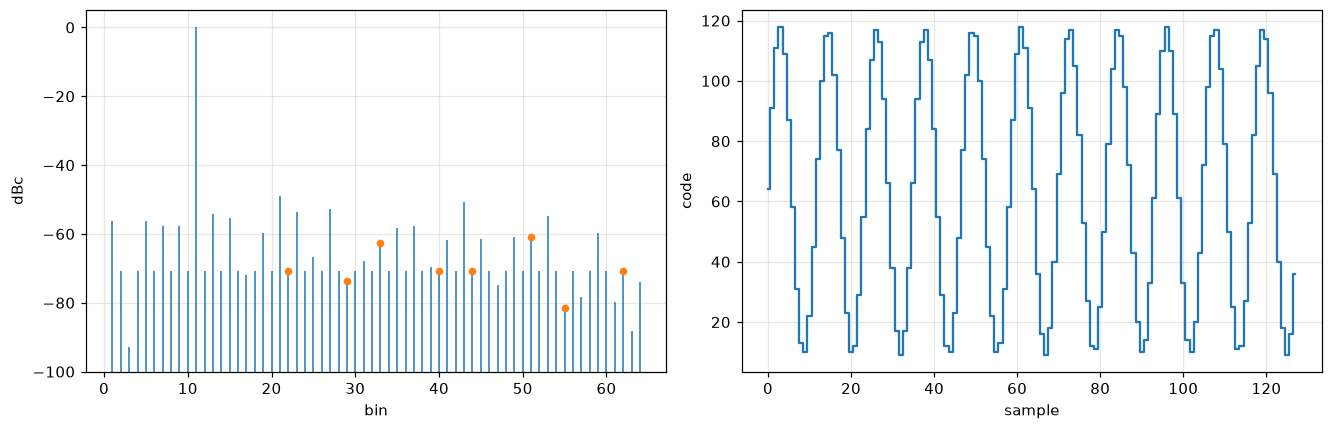

In [3]:
def spectrum(x):
    x = np.asarray(x, float) - np.mean(x)
    n = len(x)
    P = np.abs(np.fft.rfft(x) / n) ** 2
    P[1:(n + 1) // 2] *= 2
    P[0] = 0.0
    hb = sorted({b if b <= n // 2 else n - b for b in ((h * a.SINE_M) % n for h in range(2, a.H_MAX + 1))} - {0, a.SINE_M})
    pf, other = P[a.SINE_M], np.delete(P, a.SINE_M)
    app = 2 * np.sqrt(2 * pf)
    sinad = 10 * np.log10(pf / other.sum())
    return dict(P=P, hb=hb, sinad=sinad, snr=10 * np.log10(pf / (other.sum() - P[hb].sum())), thd=10 * np.log10(P[hb].sum() / pf),
                sfdr=10 * np.log10(pf / other.max()), app=app, enob=(sinad - 1.76 + 20 * np.log10(N / app)) / 6.02)

W = conversions(DATA / 'adc_sine_a.raw')
off = np.abs(W.code - np.interp(W.vd, vd, code)) > a.SINE_TOL
m = spectrum(W.code)
gs, cs = np.polyfit(W.vd, W.code + 0.5, 1)
mi = spectrum(np.clip(np.floor(gs * W.vd + cs), 0, N - 1))
print(f"{len(W)} samples, {a.SINE_M} cycles, {m['app']:.1f} codes p-p ({100 * m['app'] / N:.0f} % of full scale)")
print(f"SINAD {m['sinad']:.2f} dB, SNR {m['snr']:.2f} dB, THD {m['thd']:.2f} dBc, SFDR {m['sfdr']:.2f} dBc, ENOB {m['enob']:.2f}")
print(f"ideal quantizer on the same samples: SINAD {mi['sinad']:.2f} dB, ENOB {mi['enob']:.2f}")
rep.check('d_out matches the SAR register (sine)', f'{int((W.code != W.dout).sum())} of {len(W)} differ', '== 0', bool((W.code == W.dout).all()))
rep.check('sine matches ramp', f'{int(off.sum())} of {len(W)} more than {a.SINE_TOL:g} codes off', '== 0', not off.any())
rep.limit('ENOB', m['enob'], '{:.2f} bit', SP['enob_min'], '>=', 'bit')
rep.limit('THD', m['thd'], '{:.1f} dBc', SP['thd_db_max'], '<=', 'dBc')
rep.limit('SFDR', m['sfdr'], '{:.1f} dBc', SP['sfdr_db_min'], '>=', 'dBc')
rep.info('SINAD / SNR', f"{m['sinad']:.1f} / {m['snr']:.1f} dB", f"ideal quantizer: {mi['sinad']:.1f} dB")

db = 10 * np.log10(np.maximum(m['P'], 1e-30) / m['P'][a.SINE_M])
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].vlines(np.arange(1, len(db)), -120, db[1:], lw=1.0); axs[0].plot(m['hb'], db[m['hb']], 'o', c='C1', ms=4)
axs[0].set(ylim=(-100, 5), xlabel='bin', ylabel='dBc')
axs[1].step(np.arange(len(W)), W.code, where='mid'); axs[1].set(xlabel='sample', ylabel='code')
plt.show()

## Summary

In [4]:
idd = np.concatenate([R.idd[R.eoc], W.idd[W.eoc]]).mean()
pw = idd * 1e-6 * S.VDD
rep.info('supply current / power', f'{idd:.1f} uA / {1e6 * pw:.1f} uW', 'digital controller not modelled')
rep.info('Walden FoM', f"{1e15 * pw / (S.F_CONV * 2 ** m['enob']):.0f} fJ/conv-step")
rep.table()

,check,value,spec,result
0,all conversions finished,0 unfinished,== 0,PASS
1,d_out matches the SAR register,0 of 513 differ,== 0,PASS
2,conversion errors,0 beyond +/-3 LSB,== 0,PASS
3,"INL, smoothed best fit (37 pt)",0.086 LSB (sweep floor 0.02),<= 0.5 LSB,PASS
4,no missing codes,0 missing,== 0,PASS
5,monotonic,0 reversals,== 0,PASS
6,gain error / offset,+0.55 % / -0.01 LSB,,INFO
7,d_out matches the SAR register (sine),0 of 128 differ,== 0,PASS
8,sine matches ramp,0 of 128 more than 1.5 codes off,== 0,PASS
9,ENOB,6.94 bit,>= 6.5 bit,PASS
